# EM segmentation of a brain-MRI slice

Each brain pixel of a T1-weighted MRI slice is assigned to one of three tissue classes — cerebrospinal fluid, gray matter, white matter — by fitting a Gaussian mixture to the pixel intensities with the Expectation-Maximization algorithm.

**Model.** Pixel $i$ has intensity $x_i$ and a hidden class $z_i \in \{1,\dots,K\}$ with $p(z_i = k) = \pi_k$ and $x_i \mid z_i = k \sim \mathcal N(\mu_k, \sigma_k^2)$.

**E-step.** $q_{ik} = \dfrac{\pi_k\,\mathcal N(x_i;\mu_k,\sigma_k^2)}{\sum_j \pi_j\,\mathcal N(x_i;\mu_j,\sigma_j^2)}$

**M-step.** $N_k = \sum_i q_{ik}$, $\quad\pi_k = N_k / n$, $\quad\mu_k = \frac{1}{N_k}\sum_i q_{ik}x_i$, $\quad\sigma_k^2 = \frac{1}{N_k}\sum_i q_{ik}(x_i-\mu_k)^2$

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt

from em_segmentation import bic, fit_gmm
from em_segmentation.mri import TISSUES, load_volume, segment_slice, take_slice
from em_segmentation import plots

## Data

A simulated T1 volume from BrainWeb and a binary brain mask (see `data/README.md`). The middle coronal slice is used; pixels outside the mask or darker than 100 are discarded.

volume: (181, 217, 181) | slice: (181, 181)


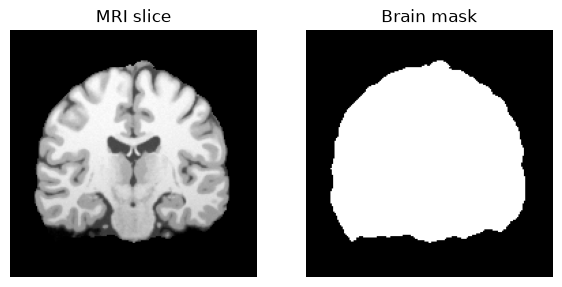

In [2]:
volume = load_volume("../data/brain.nii.gz")
mask_volume = load_volume("../data/brain_mask.nii")
image, mask = take_slice(volume, "coronal"), take_slice(mask_volume, "coronal")
print("volume:", volume.shape, "| slice:", image.shape)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, im, title in zip(axes, (image, mask), ("MRI slice", "Brain mask")):
    ax.imshow(np.rot90(im, k=plots.ROTATIONS), cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()

## Fit

EM starts from equal weights, means spread evenly over the intensity range and a common variance. It stops when the relative increase of the log-likelihood falls below $10^{-8}$.

In [3]:
snapshots = {}
def record(iteration, weights, means, variances):
    if iteration in (1, 10, 50):
        snapshots[iteration] = (weights.copy(), means.copy(), variances.copy())

labels, fit, valid = segment_slice(image, mask, n_components=3, min_intensity=100, callback=record)
pixels = image[valid]
snapshots[fit.n_iter] = (fit.weights, fit.means, fit.variances)

print(f"{pixels.size} pixels, {fit.n_iter} iterations, converged: {fit.converged}")
for k, name in enumerate(TISSUES):
    print(f"{name:20s} weight {fit.weights[k]:.3f}   mean {fit.means[k]:6.1f}   std {np.sqrt(fit.variances[k]):5.1f}   pixels {(fit.labels == k).sum()}")

14973 pixels, 108 iterations, converged: True
Cerebrospinal fluid  weight 0.119   mean  268.3   std  66.0   pixels 1799
Gray matter          weight 0.722   mean  618.7   std  98.6   pixels 10421
White matter         weight 0.159   mean  791.8   std  13.6   pixels 2753


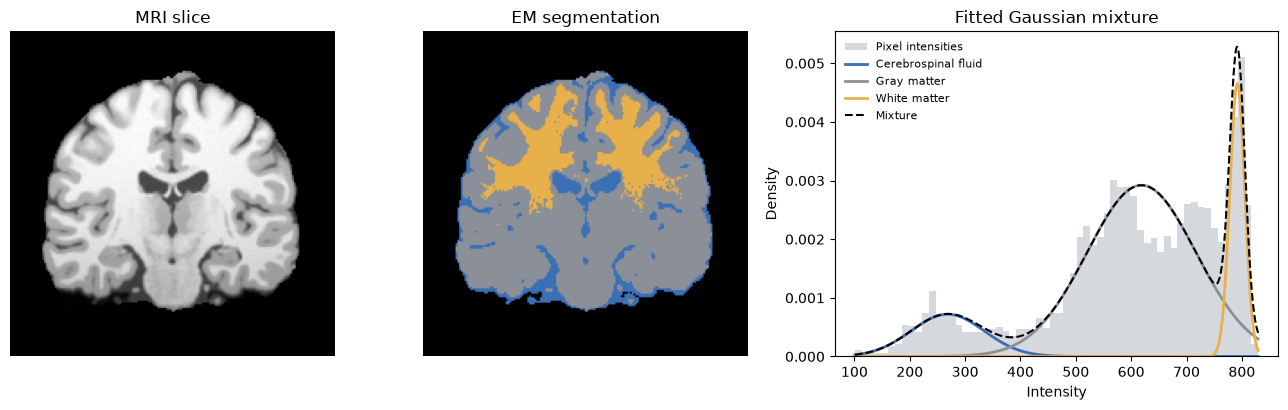

In [4]:
plots.summary_figure(image, labels, pixels, fit); plt.show()

## Convergence

Each EM iteration maximises a lower bound of the log-likelihood that is tight at the current parameters, so the log-likelihood cannot decrease.

smallest increase between two iterations: 0.0007432228740071878


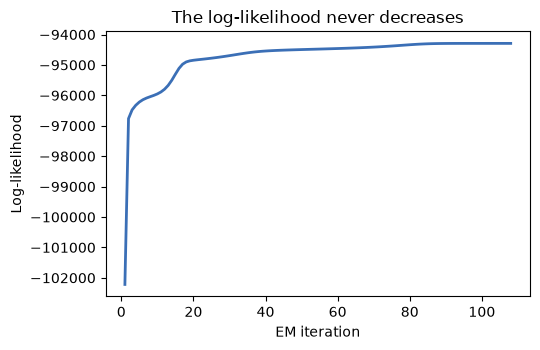

In [5]:
history = np.array(fit.log_likelihoods)
print("smallest increase between two iterations:", np.diff(history).min())
plots.convergence_figure(fit); plt.show()

## The segmentation keeps changing long after the curve looks flat

After 50 iterations the mixture already fits the histogram well, but the white-matter component is still narrowing: between iteration 50 and convergence its standard deviation drops from about 31 to 14 and a third of its pixels move to the gray-matter class.

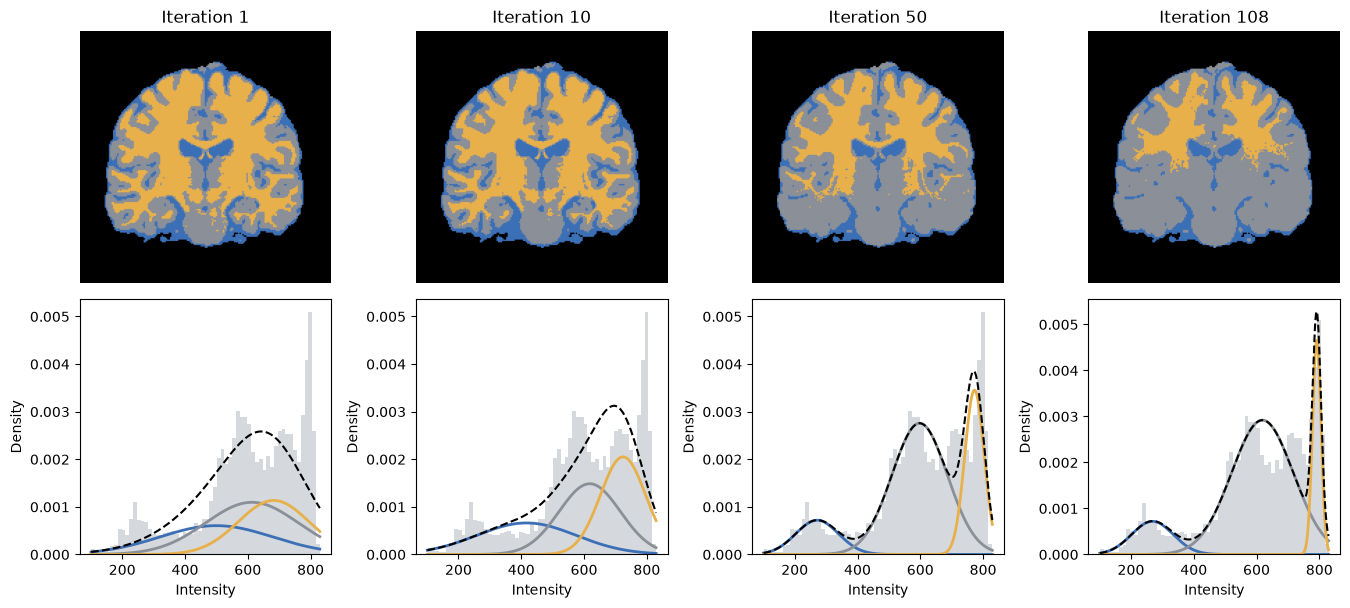

iteration   1   weights [0.274 0.405 0.321]   means [499.9 613.3 682.5]   stds [180.2 147.5 112.6]
iteration  10   weights [0.263 0.364 0.372]   means [416.4 618.1 724.1]   stds [158.5  97.8  72.4]
iteration  50   weights [0.123 0.61  0.267]   means [271.5 597.9 772.6]   stds [68.1 88.3 30.8]
iteration 108   weights [0.119 0.722 0.159]   means [268.3 618.7 791.8]   stds [66.  98.6 13.6]


In [6]:
plots.iterations_figure(image, mask, pixels, snapshots, valid); plt.show()
for iteration, (w, m, v) in snapshots.items():
    order = np.argsort(m)
    print(f"iteration {iteration:3d}   weights {np.round(w[order], 3)}   means {np.round(m[order], 1)}   stds {np.round(np.sqrt(v[order]), 1)}")

## How many classes do the intensities support?

Three classes are an anatomical choice. The histogram itself has a fourth mode around 730, between the gray-matter bulk and the sharp white-matter peak, and the Bayesian information criterion prefers more than three components.

In [7]:
print("K   iterations   log-likelihood        BIC   means")
for k in range(1, 7):
    candidate = fit_gmm(pixels, n_components=k, max_iter=5000, tol=1e-10)
    ll = candidate.log_likelihoods[-1]
    print(f"{k}   {candidate.n_iter:10d}   {ll:14.1f}   {bic(ll, k, pixels.size):9.1f}   {np.round(candidate.means, 0)}")

K   iterations   log-likelihood        BIC   means
1            3         -97569.5    195158.3   [604.]


2          126         -95892.3    191832.6   [266. 649.]


3          119         -94290.7    188658.2   [268. 619. 792.]


4          250         -93746.5    187598.7   [275. 579. 730. 795.]


5          448         -93680.0    187494.6   [236. 327. 580. 727. 795.]


6         5000         -93679.0    187521.5   [236. 340. 546. 617. 729. 795.]
